# 実験1 (ex001): 高次元潜在空間 ($K=256$) における Deep VIB の学習と正則化性能の評価

本ノートブックでは，Alemi et al. (ICLR 2017) "Deep Variational Information Bottleneck" の **Section 4.1.1 (Higher Dimensional Embedding, Table 1, Figure 1(a)(c)(d))** の再現実験を行う．

## 実験内容
1. **正則化手法の比較 (Table 1 の再現)**:
   - 順列不変 (Permutation-Invariant) MNIST ($784 \to 1024 \to 1024 \to 256 \to 10$) において，決定論的ベースライン (Baseline)，Dropout，Confidence Penalty (Pereyra et al., 2017)，Label Smoothing，および Deep VIB をすべて論文 Appendix A 準拠の200エポック・Polyak移動平均で学習し，テスト誤分類率を比較する．
2. **トレードオフ係数 $\beta$ のスイープ実験 (Figure 1(a)(c)(d) の再現)**:
   - $\beta \in \{0, 10^{-6}, 10^{-5}, 10^{-4}, 3\times 10^{-4}, 10^{-3}, 3\times 10^{-3}, 10^{-2}, 10^{-1}, 10^0\}$ にわたって Deep VIB ($K=256$) を学習し，1サンプル評価 (`1 shot eval`) と12サンプルモンテカルロ平均評価 (`avg eval`) の誤分類率，および相互情報量 $I(Z, X)$, $I(Z, Y)$ の推移を定量・可視化する．

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from model import DeepVIB, DeterministicMLP
from utils import (
    set_seed,
    load_mnist_gpu,
    train_vib_model,
    evaluate_vib,
    train_deterministic_model,
    evaluate_deterministic,
)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

os.makedirs("checkpoints", exist_ok=True)
os.makedirs("../report/img", exist_ok=True)

# MNISTデータのGPUメモリへの読み込み (画素値 [-1, 1] スケーリング)
train_x, train_y, test_x, test_y = load_mnist_gpu("../datasets", device=device)
print(f"Train shape: {train_x.shape}, Test shape: {test_x.shape}, Range: [{train_x.min().item():.1f}, {train_x.max().item():.1f}]")

Using device: cuda (NVIDIA GeForce RTX 4080)
Train shape: torch.Size([60000, 784]), Test shape: torch.Size([10000, 784]), Range: [-1.0, 1.0]


## 1. 決定論的ベースラインおよび各種正則化手法の学習 (Table 1)

論文 Section 4.1.1 (Table 1) に従い，以下の比較手法を 200 エポック学習する:
- **Baseline**: 正則化なしの決定論的 MLP
- **Dropout**: 隠れ層に Dropout ($p=0.25$) を適用
- **Confidence Penalty**: $J_{\mathrm{CP}} = H(p(y|y_n), p(y|x_n)) - \beta_{\mathrm{CP}} H(p(y|x_n))$ ($\beta_{\mathrm{CP}} = 0.15$)
- **Label Smoothing**: One-hot ラベルの $0$ を $\epsilon = 0.01$ に置換して正規化

In [2]:
det_configs = [
    {"name": "Baseline", "reg_type": "baseline", "reg_param": 0.0, "dropout": 0.0, "ckpt": "checkpoints/baseline.pt"},
    {"name": "Dropout", "reg_type": "dropout", "reg_param": 0.0, "dropout": 0.25, "ckpt": "checkpoints/dropout.pt"},
    {"name": "Confidence Penalty", "reg_type": "confidence_penalty", "reg_param": 0.15, "dropout": 0.0, "ckpt": "checkpoints/cp.pt"},
    {"name": "Label Smoothing", "reg_type": "label_smoothing", "reg_param": 0.01, "dropout": 0.0, "ckpt": "checkpoints/ls.pt"},
]

det_results = []
det_histories = {}

for cfg in det_configs:
    set_seed(42)
    model = DeterministicMLP(dropout_rate=cfg["dropout"]).to(device)
    ema_model, hist = train_deterministic_model(
        model,
        train_x,
        train_y,
        test_x,
        test_y,
        reg_type=cfg["reg_type"],
        reg_param=cfg["reg_param"],
        epochs=200,
        record_every=20,
        desc=f"Train {cfg['name']}"
    )
    torch.save(ema_model.state_dict(), cfg["ckpt"])
    det_histories[cfg["name"]] = hist
    final_train_err = hist[-1]["train_err"]
    final_test_err = hist[-1]["test_err"]
    det_results.append({
        "Model": cfg["name"],
        "Train Error (%)": round(final_train_err * 100, 2),
        "Test Error (%)": round(final_test_err * 100, 2),
    })
    print(f"[{cfg['name']}] Final Train Error: {final_train_err*100:.2f}%, Test Error: {final_test_err*100:.2f}%")

[Baseline] Final Train Error: 0.00%, Test Error: 1.40%
[Dropout] Final Train Error: 0.00%, Test Error: 1.34%
[Confidence Penalty] Final Train Error: 0.00%, Test Error: 1.25%
[Label Smoothing] Final Train Error: 0.00%, Test Error: 1.29%


Train Label Smoothing: 100%|##########| 200/200 [00:30<00:00,  6.54it/s, test_err=1.29%]


## 2. Deep VIB ($K=256$) の $\beta$ スイープ実験 (Figure 1(a)(c)(d))

$\beta \in \{0, 10^{-6}, 10^{-5}, 10^{-4}, 3\times 10^{-4}, 10^{-3}, 3\times 10^{-3}, 10^{-2}, 10^{-1}, 10^0\}$ について 200 エポック学習を行い，情報量制約の強さと汎化性能・相互情報量の関係を検証する．

In [3]:
beta_list = [0.0, 1e-6, 1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 1e-1, 1.0]
vib_results = []
vib_histories = {}

for beta in beta_list:
    set_seed(42)
    vib_model = DeepVIB(latent_dim=256).to(device)
    label_str = f"beta={beta:.0e}" if beta > 0 else "beta=0"
    ema_vib, hist = train_vib_model(
        vib_model,
        train_x,
        train_y,
        test_x,
        test_y,
        beta=beta,
        epochs=200,
        record_every=20,
        desc=f"VIB ({label_str})"
    )
    ckpt_name = f"checkpoints/vib_beta_{beta:.0e}.pt" if beta > 0 else "checkpoints/vib_beta_0.pt"
    torch.save(ema_vib.state_dict(), ckpt_name)
    vib_histories[beta] = hist

    last = hist[-1]
    vib_results.append({
        "beta": beta,
        "label": label_str,
        "train_err_1shot": last["train_err_1shot"],
        "train_err_mc": last["train_err_mc"],
        "test_err_1shot": last["test_err_1shot"],
        "test_err_mc": last["test_err_mc"],
        "test_err_mean": last["test_err_mean"],
        "train_izx": last["train_izx"],
        "train_izy": last["train_izy"],
        "test_izx": last["test_izx"],
        "test_izy": last["test_izy"],
    })
    print(
        f"[VIB {label_str}] Test MC Err: {last['test_err_mc']*100:.2f}%, "
        f"1-shot Err: {last['test_err_1shot']*100:.2f}%, "
        f"I(Z,X): {last['test_izx']:.2f} bits, I(Z,Y): {last['test_izy']:.3f} bits"
    )

df_vib = pd.DataFrame(vib_results)
df_vib.to_csv("checkpoints/ex001_vib_results.csv", index=False)
df_vib

[VIB beta=0] Test MC Err: 1.47%, 1-shot Err: 1.46%, I(Z,X): 3372.51 bits, I(Z,Y): 3.140 bits
[VIB beta=1e-06] Test MC Err: 1.16%, 1-shot Err: 1.24%, I(Z,X): 168.08 bits, I(Z,Y): 3.245 bits
[VIB beta=1e-05] Test MC Err: 1.30%, 1-shot Err: 1.35%, I(Z,X): 80.59 bits, I(Z,Y): 3.255 bits
[VIB beta=1e-04] Test MC Err: 1.06%, 1-shot Err: 1.43%, I(Z,X): 41.65 bits, I(Z,Y): 3.262 bits
[VIB beta=3e-04] Test MC Err: 1.23%, 1-shot Err: 1.52%, I(Z,X): 30.23 bits, I(Z,Y): 3.258 bits
[VIB beta=1e-03] Test MC Err: 1.24%, 1-shot Err: 1.78%, I(Z,X): 22.26 bits, I(Z,Y): 3.257 bits
[VIB beta=3e-03] Test MC Err: 1.31%, 1-shot Err: 2.06%, I(Z,X): 17.29 bits, I(Z,Y): 3.248 bits
[VIB beta=1e-02] Test MC Err: 1.39%, 1-shot Err: 2.63%, I(Z,X): 13.14 bits, I(Z,Y): 3.231 bits
[VIB beta=1e-01] Test MC Err: 1.52%, 1-shot Err: 8.72%, I(Z,X): 6.82 bits, I(Z,Y): 3.081 bits
[VIB beta=1e+00] Test MC Err: 78.25%, 1-shot Err: 85.45%, I(Z,X): 0.04 bits, I(Z,Y): 0.065 bits


VIB (beta=1e+00): 100%|##########| 200/200 [00:41<00:00,  4.88it/s, test_mc=78.25%, I(Z,X)=0.0b]


,beta,label,train_err_1shot,train_err_mc,test_err_1shot,test_err_mc,test_err_mean,train_izx,train_izy,test_izx,test_izy
0,0.000000,beta=0,0.000000,0.000000,0.0146,0.0147,0.0147,3339.194133,3.321928,3372.513200,3.139509
1,0.000001,beta=1e-06,0.000000,0.000000,0.0124,0.0116,0.0118,169.004717,3.321910,168.077450,3.245165
2,0.000010,beta=1e-05,0.000033,0.000000,0.0135,0.0130,0.0123,80.932450,3.321833,80.593238,3.254534
3,0.000100,beta=1e-04,0.000017,0.000000,0.0143,0.0106,0.0113,41.883896,3.321480,41.650950,3.262345
4,0.000300,beta=3e-04,0.000100,0.000000,0.0152,0.0123,0.0119,30.604783,3.320861,30.234362,3.258324
5,0.001000,beta=1e-03,0.000417,0.000000,0.0178,0.0124,0.0120,22.717819,3.319178,22.258102,3.257340
6,0.003000,beta=3e-03,0.001583,0.000000,0.0206,0.0131,0.0124,17.761567,3.315082,17.287805,3.247896
7,0.010000,beta=1e-02,0.005467,0.000000,0.0263,0.0139,0.0138,13.566538,3.302937,13.137064,3.231318
8,0.100000,beta=1e-01,0.060400,0.000067,0.0872,0.0152,0.0132,7.071939,3.165269,6.819499,3.081113
9,1.000000,beta=1e+00,0.857850,0.777117,0.8545,0.7825,0.6443,0.039308,0.066225,0.042140,0.065320


In [4]:
# Table 1 の総合比較表の作成
best_vib_row = df_vib.loc[df_vib["test_err_mc"].idxmin()]
vib_1e3_row = df_vib[df_vib["beta"] == 1e-3].iloc[0]
vib_3e4_row = df_vib[df_vib["beta"] == 3e-4].iloc[0]
vib_0_row = df_vib[df_vib["beta"] == 0.0].iloc[0]

table1_rows = det_results + [
    {
        "Model": "VIB (beta = 0)",
        "Train Error (%)": round(vib_0_row["train_err_mc"] * 100, 2),
        "Test Error (%)": round(vib_0_row["test_err_mc"] * 100, 2),
    },
    {
        "Model": "VIB (beta = 3e-4)",
        "Train Error (%)": round(vib_3e4_row["train_err_mc"] * 100, 2),
        "Test Error (%)": round(vib_3e4_row["test_err_mc"] * 100, 2),
    },
    {
        "Model": "VIB (beta = 1e-3)",
        "Train Error (%)": round(vib_1e3_row["train_err_mc"] * 100, 2),
        "Test Error (%)": round(vib_1e3_row["test_err_mc"] * 100, 2),
    },
]
df_table1 = pd.DataFrame(table1_rows)
df_table1.to_csv("checkpoints/ex001_table1.csv", index=False)
df_table1

,Model,Train Error (%),Test Error (%)
0,Baseline,0.0,1.40
1,Dropout,0.0,1.34
2,Confidence Penalty,0.0,1.25
3,Label Smoothing,0.0,1.29
4,VIB (beta = 0),0.0,1.47
5,VIB (beta = 3e-4),0.0,1.23
6,VIB (beta = 1e-3),0.0,1.24


## 3. 実験結果の可視化 (Figure 1(a)(c)(d), Table 1 比較, 学習推移)

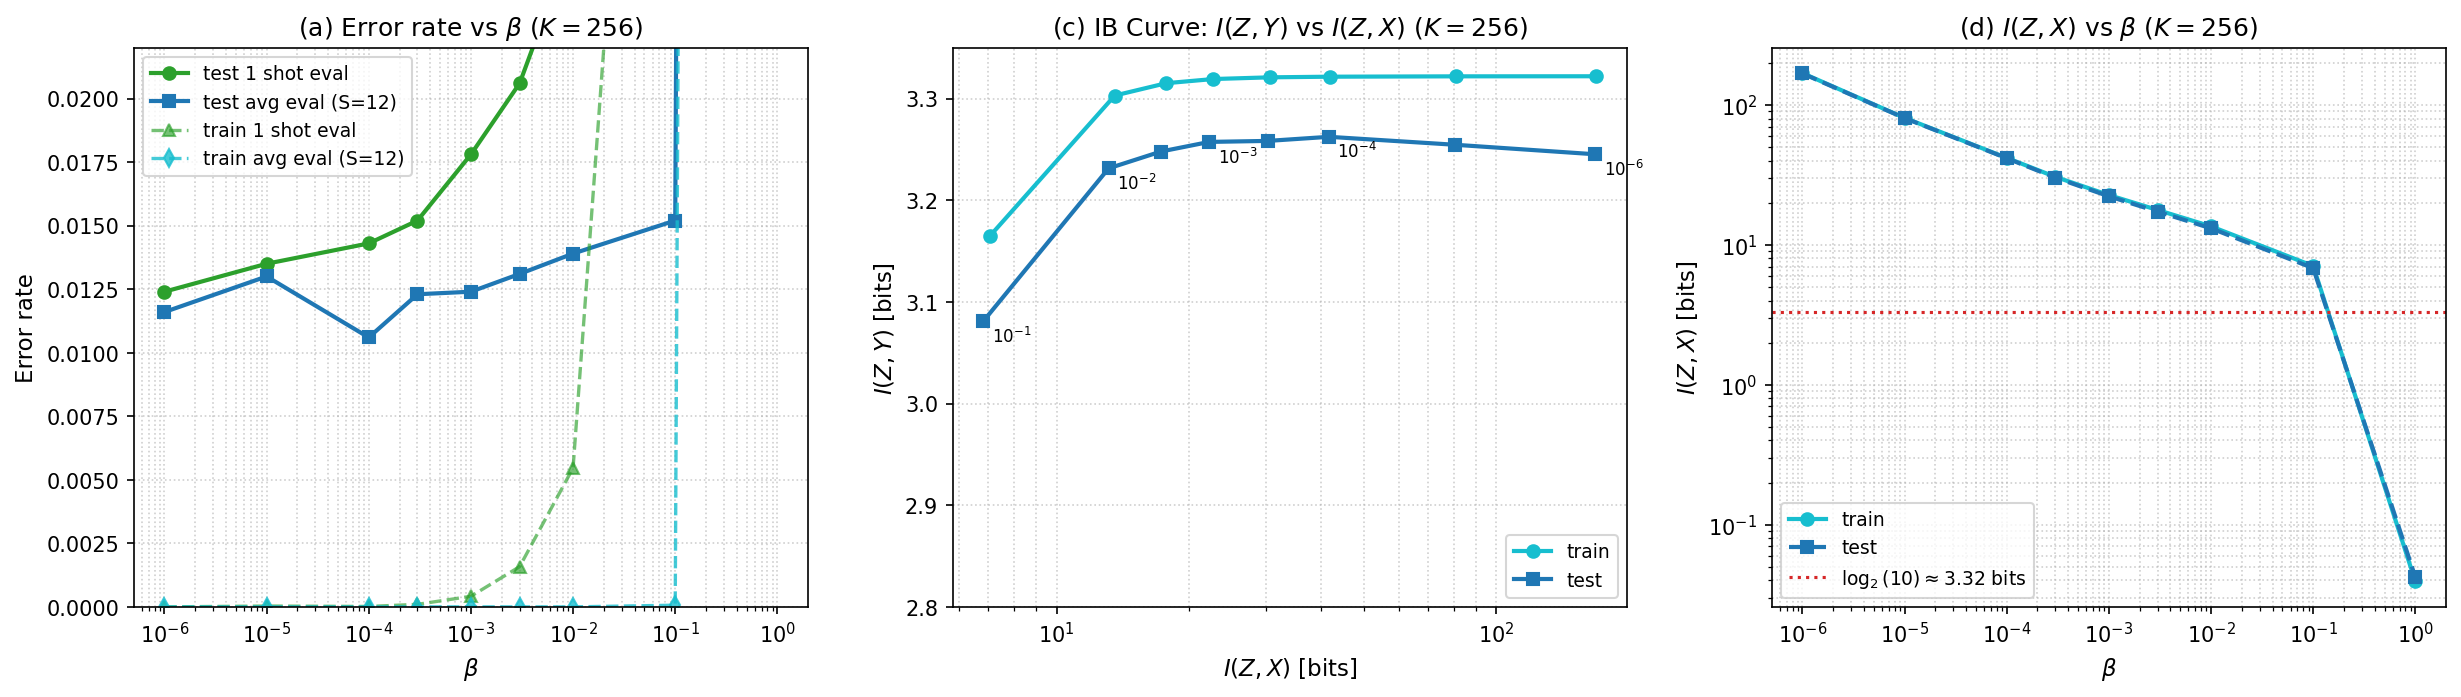

In [5]:
# 1. 論文 Figure 1(a), 1(c), 1(d) の再現プロット
df_pos = df_vib[df_vib["beta"] > 0].copy()

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# (a) Error rate vs beta (K=256)
ax = axes[0]
ax.plot(df_pos["beta"], df_pos["test_err_1shot"], "o-", color="#2ca02c", lw=2, label="test 1 shot eval")
ax.plot(df_pos["beta"], df_pos["test_err_mc"], "s-", color="#1f77b4", lw=2, label="test avg eval (S=12)")
ax.plot(df_pos["beta"], df_pos["train_err_1shot"], "^--", color="#2ca02c", alpha=0.65, lw=1.6, label="train 1 shot eval")
ax.plot(df_pos["beta"], df_pos["train_err_mc"], "d--", color="#17becf", alpha=0.8, lw=1.6, label="train avg eval (S=12)")
ax.set_xscale("log")
ax.set_ylim(0.0, 0.022)
ax.set_xlabel("$\\beta$", fontsize=11)
ax.set_ylabel("Error rate", fontsize=11)
ax.set_title("(a) Error rate vs $\\beta$ ($K=256$)", fontsize=12)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(fontsize=9, loc="upper left")

# (c) IB Curve: I(Z, Y) vs I(Z, X)
ax = axes[1]
df_ib = df_pos[df_pos["beta"] <= 1e-1].sort_values("train_izx")
ax.plot(df_ib["train_izx"], df_ib["train_izy"], "o-", color="#17becf", lw=2, label="train")
ax.plot(df_ib["test_izx"], df_ib["test_izy"], "s-", color="#1f77b4", lw=2, label="test")
for _, r in df_ib.iterrows():
    ax.annotate(f"$10^{{{int(round(np.log10(r['beta'])))}}}$" if r["beta"] in [1e-6, 1e-4, 1e-3, 1e-2, 1e-1] else "",
                (r["test_izx"], r["test_izy"]), textcoords="offset points", xytext=(4, -10), fontsize=8)
ax.set_xscale("log")
ax.set_ylim(2.8, 3.35)
ax.set_xlabel("$I(Z, X)$ [bits]", fontsize=11)
ax.set_ylabel("$I(Z, Y)$ [bits]", fontsize=11)
ax.set_title("(c) IB Curve: $I(Z, Y)$ vs $I(Z, X)$ ($K=256$)", fontsize=12)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(fontsize=9, loc="lower right")

# (d) I(Z, X) vs beta
ax = axes[2]
ax.plot(df_pos["beta"], df_pos["train_izx"].clip(lower=1e-4), "o-", color="#17becf", lw=2, label="train")
ax.plot(df_pos["beta"], df_pos["test_izx"].clip(lower=1e-4), "s--", color="#1f77b4", lw=2, label="test")
ax.axhline(np.log2(10.0), color="#d62728", ls=":", lw=1.5, label="$\\log_2(10) \\approx 3.32$ bits")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("$\\beta$", fontsize=11)
ax.set_ylabel("$I(Z, X)$ [bits]", fontsize=11)
ax.set_title("(d) $I(Z, X)$ vs $\\beta$ ($K=256$)", fontsize=12)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(fontsize=9, loc="lower left")

plt.tight_layout()
plt.savefig("../report/img/ex001_fig1_k256.png", dpi=180, bbox_inches="tight")
plt.show()

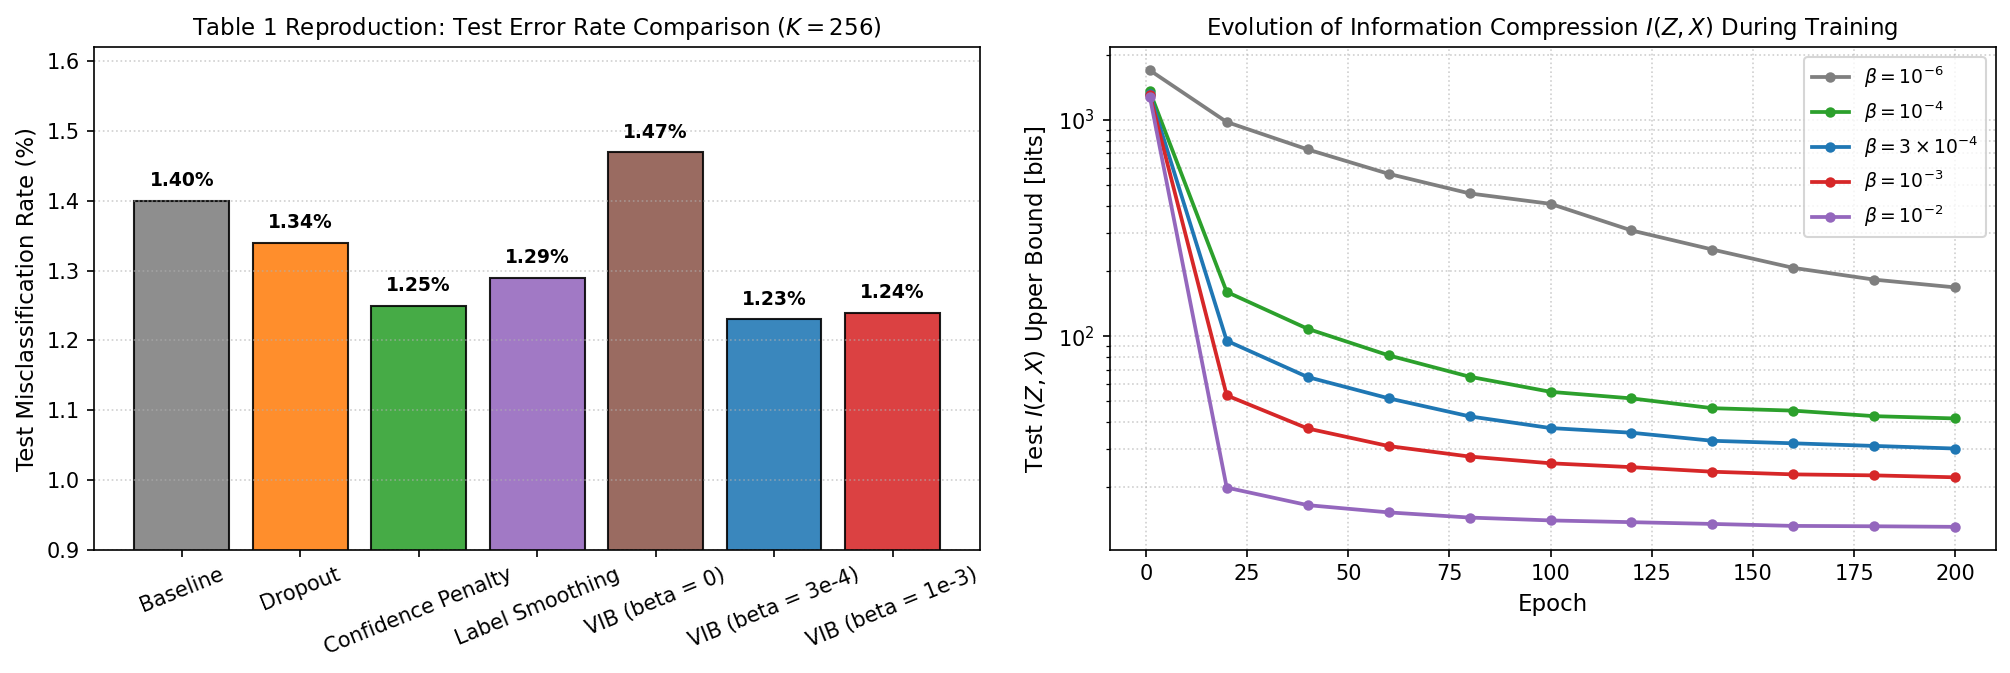

In [6]:
# 2. Table 1 正則化手法のテスト誤分類率比較と学習曲線
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

ax = axes[0]
colors = ["#7f7f7f", "#ff7f0e", "#2ca02c", "#9467bd", "#8c564b", "#1f77b4", "#d62728"]
bars = ax.bar(df_table1["Model"], df_table1["Test Error (%)"], color=colors[:len(df_table1)], edgecolor="black", alpha=0.88)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, h + 0.015, f"{h:.2f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_ylim(0.9, max(df_table1["Test Error (%)"]) + 0.15)
ax.set_ylabel("Test Misclassification Rate (%)", fontsize=11)
ax.set_title("Table 1 Reproduction: Test Error Rate Comparison ($K=256$)", fontsize=11)
ax.tick_params(axis="x", rotation=22)
ax.grid(axis="y", ls=":", alpha=0.6)

# 学習エポックに伴う相互情報量 I(Z, X) とテスト誤差の推移
ax2 = axes[1]
for beta_val, color, lbl in [(1e-6, "#7f7f7f", "$\\beta=10^{-6}$"), (1e-4, "#2ca02c", "$\\beta=10^{-4}$"), (3e-4, "#1f77b4", "$\\beta=3\\times 10^{-4}$"), (1e-3, "#d62728", "$\\beta=10^{-3}$"), (1e-2, "#9467bd", "$\\beta=10^{-2}$")]:
    h_df = pd.DataFrame(vib_histories[beta_val])
    ax2.plot(h_df["epoch"], h_df["test_izx"], "o-", ms=4, lw=1.8, color=color, label=lbl)
ax2.set_yscale("log")
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Test $I(Z, X)$ Upper Bound [bits]", fontsize=11)
ax2.set_title("Evolution of Information Compression $I(Z, X)$ During Training", fontsize=11)
ax2.grid(True, which="both", ls=":", alpha=0.6)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig("../report/img/ex001_table1_and_dynamics.png", dpi=180, bbox_inches="tight")
plt.show()